<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/15_Lab_GNN_MACE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 15 — GNN y MACE para sistemas físicos

En este laboratorio entrenamos redes de paso de mensajes sobre dos sistemas físicos y usamos un potencial interatómico aprendido, MACE-MP-0.

**Antes de empezar:** active la GPU de Colab. Con el menú en español: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4 → Guardar*. Con el menú en inglés: *Runtime → Change runtime type → T4 GPU → Save*. Las celdas marcadas `# COMPLETAR` son las suyas; cada una viene con una prueba que dice si quedó bien. Los ejercicios previos traen su solución en una celda oculta (*Mostrar código*); úsela solo para comprobar. En la sesión 5, después de una pausa, Colab habrá olvidado lo que se ejecutó en la sesión 4: vuelva a ejecutar la **Preparación** y siga directamente con la parte A1; las partes A y B no dependen de los ejercicios previos. La descarga de los datos de A2 tarda unos minutos: ejecútela al empezar, mientras trabaja en A1.

# Preparación

En Colab, PyTorch ya viene instalado. Instalamos PyTorch Geometric, MACE (que trae ASE) y `spglib`, que identifica el grupo espacial de un cristal. Si Colab pide reiniciar el entorno después de la instalación, hágalo y siga desde la celda de librerías.

In [ ]:
!pip install -q torch_geometric mace-torch spglib

In [ ]:
import gzip
import json
import requests
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from scipy.spatial import cKDTree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

import torch
from torch.nn import functional as fn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import from_networkx, to_dense_adj, to_undirected
from torch_geometric.nn import GCNConv, CGConv, global_mean_pool

from ase import Atoms
from ase.build import bulk
from ase.neighborlist import neighbor_list
from ase.eos import EquationOfState
from ase.units import GPa
import spglib

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", dispositivo)

dispositivo: cpu


# Ejercicios previos (al final de la sesión 4)

Cuatro ejercicios cortos que preparan las partes A2 y B. Se hacen en clase con el docente; lo que no se termine se completa antes del laboratorio.

## Previo 1. Lectura del grafo: ¿suma o media?

Para predecir una propiedad del grafo completo se reúnen los estados de los nodos con una función invariante: la suma, la media o el máximo. Complete `lectura` y aplíquela a un triángulo y a dos copias de él, con el grado de cada nodo como estado.

In [ ]:
def lectura(h):
    """Suma, media y máximo de los estados h (un arreglo con un valor por nodo)."""
    return h.sum(), h.mean(), h.max()

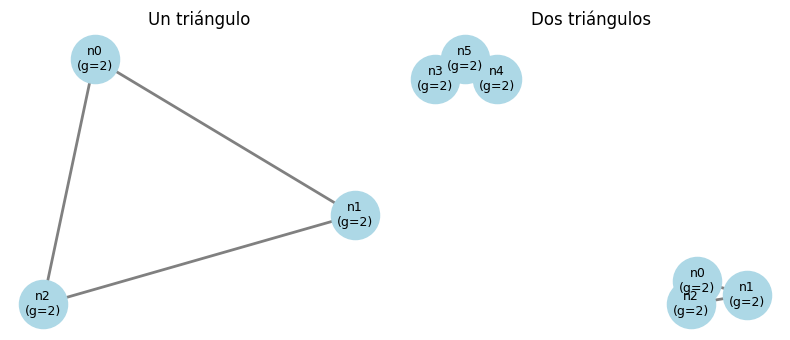

un triángulo    suma =    6   media = 2.00   máximo = 2
dos triángulos  suma =   12   media = 2.00   máximo = 2


In [ ]:
triangulo = nx.cycle_graph(3)
dos_triangulos = nx.disjoint_union(triangulo, triangulo)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

for ax, (nombre, G) in zip(axes, [("Un triángulo", triangulo), ("Dos triángulos", dos_triangulos)]):
    # Calculamos posiciones (spring_layout separa bien los dos componentes)
    pos = nx.spring_layout(G, seed=42)

    # Etiquetamos cada nodo con su grado (cantidad de conexiones)
    etiquetas = {nodo: f"n{nodo}\n(g={grado})" for nodo, grado in G.degree()}

    nx.draw(G, pos, ax=ax, labels=etiquetas, with_labels=True,
            node_color="lightblue", node_size=1200, font_size=9, edge_color="gray", width=2)
    ax.set_title(nombre)

plt.tight_layout()
plt.show()


for nombre, G in [("un triángulo", triangulo), ("dos triángulos", dos_triangulos)]:
    h = np.array([grado for _, grado in G.degree()], dtype=float)
    s, m, x = lectura(h)
    print(f"{nombre:15s} suma = {s:4.0f}   media = {m:.2f}   máximo = {x:.0f}")

**Responda:** ¿Cuál de las tres lecturas distingue un grafo de dos copias de sí mismo? La energía de un cristal es **extensiva**: si se duplica la celda, se duplica. El módulo de compresibilidad es **intensivo**: no cambia. ¿Qué lectura usaría para cada una?

> Únicamente la suma (h.sum()) logra distinguirlas, ya que pasa de $6$ en un triángulo a $12$ en dos triángulos separados. Por el contrario, tanto la media como el máximo valen $2$ en ambos casos.

> Para la energía se debe usar la suma. Al ser una propiedad aditiva ($E = \sum E_i$), si se duplica el tamaño del grafo o de la celda, el valor total también debe duplicarse. Mientras que para  el módulo de compresibilidad se debe usar la media. Una misma red cristalina puede representarse mediante una celda primitiva pequeña o mediante una supercelda más grande; como una propiedad intensiva no debe depender de esa elección arbitraria de tamaño, la media garantiza que el resultado se mantenga invariante.





In [ ]:
#@title Solución del previo 1
def lectura(h):
    """Suma, media y máximo de los estados h (un arreglo con un valor por nodo)."""
    return h.sum(), h.mean(), h.max()

for nombre, G in [("un triángulo", triangulo), ("dos triángulos", dos_triangulos)]:
    h = np.array([grado for _, grado in G.degree()], dtype=float)
    s, m, x = lectura(h)
    print(f"{nombre:15s} suma = {s:4.0f}   media = {m:.2f}   máximo = {x:.0f}")
# Solo la suma distingue las dos copias (6 frente a 12): la media y el máximo valen 2 en ambos.
# Energía (extensiva): suma, E = suma de las E_i. Módulo de compresibilidad (intensivo): media.
# Una misma red cristalina se puede describir con una celda primitiva o con una celda más
# grande; una propiedad intensiva no debe depender de esa elección, y la media no depende.

un triángulo    suma =    6   media = 2.00   máximo = 2
dos triángulos  suma =   12   media = 2.00   máximo = 2


## Previo 2. Mini-lotes: una matriz diagonal por bloques

PyG entrena con varios grafos a la vez uniéndolos en un solo grafo desconectado. Construimos tres grafos pequeños, con el grado como atributo de cada nodo, y los juntamos en un lote con `DataLoader`.

In [ ]:
def k4_menos_arista():
    """ Genera un grafo completo y después elimina la conexión entre los nodos 0 y 2"""
    G = nx.complete_graph(4)
    G.remove_edge(0, 2)
    return G

grafos = [nx.cycle_graph(3), nx.cycle_graph(6), k4_menos_arista()]

lista = []

for G in grafos:
    dato = from_networkx(G)
    dato.x = torch.tensor([[float(G.degree(u))] for u in G.nodes()])
    lista.append(dato)

lote = next(iter(DataLoader(lista, batch_size=3)))
print(lote)
print("batch =", lote.batch.tolist())

DataBatch(edge_index=[2, 28], num_nodes=13, x=[13, 1], batch=[13], ptr=[4])
batch = [0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2]


Complete la celda siguiente: obtenga la matriz de adyacencia densa del lote con `to_dense_adj(lote.edge_index)[0]` y dibújela con `plt.imshow`; luego calcule la lectura de media de cada grafo con `global_mean_pool(lote.x, lote.batch)` y compruebe que coincide con el grado medio de cada uno.

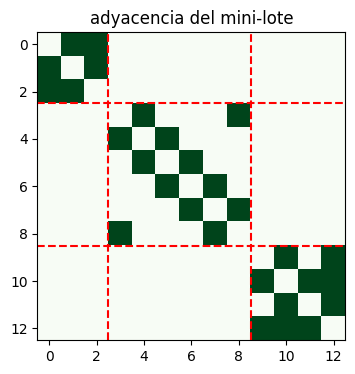

media por grafo: [2.0, 2.0, 2.5]


In [ ]:
A_lote = to_dense_adj(lote.edge_index)[0]

plt.figure(figsize=(4, 4))
plt.imshow(A_lote.numpy(), cmap="Greens")

# Líneas punteadas para separar los grafos del lote
cortes = lote.batch.bincount().cumsum(0)[:-1] - 0.5
for c in cortes:
    plt.axhline(c.item(), color="red", linestyle="--")
    plt.axvline(c.item(), color="red", linestyle="--")

plt.title("adyacencia del mini-lote")
plt.show()

medias = global_mean_pool(lote.x, lote.batch).flatten()

print("media por grafo:", medias.tolist())

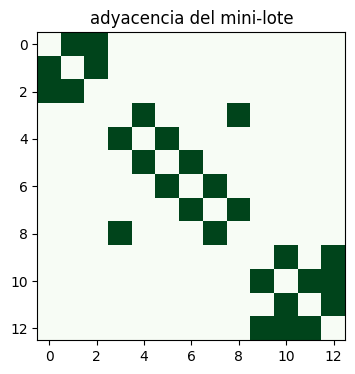

media por grafo: [2.0, 2.0, 2.5]
grado medio:     [np.float64(2.0), np.float64(2.0), np.float64(2.5)]


In [ ]:
#@title Solución del previo 2
A_lote = to_dense_adj(lote.edge_index)[0]
plt.figure(figsize=(4, 4))
plt.imshow(A_lote.numpy(), cmap="Greens")
plt.title("adyacencia del mini-lote")
plt.show()

medias = global_mean_pool(lote.x, lote.batch).flatten()
print("media por grafo:", medias.tolist())
print("grado medio:    ", [np.mean([g for _, g in G.degree()]) for G in grafos])
# Tres bloques sobre la diagonal (3, 6 y 4 nodos) y ceros fuera de ellos: los mensajes
# no cruzan de un grafo a otro. Las medias son 2, 2 y 2,5.

## Previo 3. El grafo radial de un cristal

En un cristal, los nodos son los átomos y hay una arista entre dos átomos a menos de un radio de corte $r_c$, contando las **imágenes periódicas**: un átomo cerca del borde de la celda tiene vecinos en la celda de al lado. ASE lo resuelve con `neighbor_list`: `i, j, d = neighbor_list("ijd", atoms, rc)` devuelve una arista dirigida $i\to j$ por cada par de átomos a menos de `rc`, con su distancia `d`.

Usamos el silicio, con estructura de diamante y $a=5{,}431$ Å. Complete `vecinos_por_atomo`.

In [ ]:
si = bulk("Si", "diamond", a=5.431)
print(si, "\nátomos en la celda primitiva:", len(si))

def vecinos_por_atomo(atoms, rc):
    """Número medio de vecinos por átomo a menos de rc (Å), con las imágenes periódicas."""
    i = neighbor_list("i", atoms, rc)
    return len(i) / len(atoms)

Atoms(symbols='Si2', pbc=True, cell=[[0.0, 2.7155, 2.7155], [2.7155, 0.0, 2.7155], [2.7155, 2.7155, 0.0]]) 
átomos en la celda primitiva: 2


In [ ]:
# Verificación del previo 3
assert vecinos_por_atomo(si, 3.0) == 4, "Cada Si tiene 4 primeros vecinos a 2,35 Å"
assert vecinos_por_atomo(si, 4.0) == 16, "Con 12 segundos vecinos a 3,84 Å suman 16"
print("Previo 3 correcto")

Previo 3 correcto


In [ ]:
#@title Solución del previo 3
def vecinos_por_atomo(atoms, rc):
    """Número medio de vecinos por átomo a menos de rc (Å), con las imágenes periódicas."""
    i = neighbor_list("i", atoms, rc)
    return len(i) / len(atoms)

assert vecinos_por_atomo(si, 3.0) == 4
assert vecinos_por_atomo(si, 4.0) == 16
print("Previo 3 correcto")

Previo 3 correcto


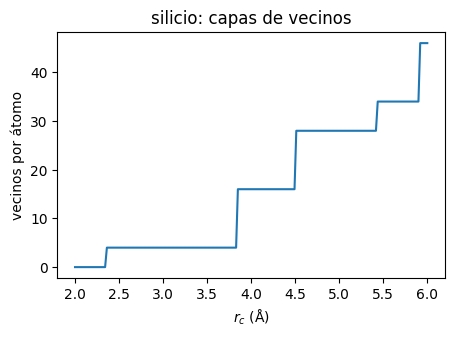

In [ ]:
radios = np.linspace(2.0, 6.0, 200)
plt.figure(figsize=(5, 3.2))
plt.plot(radios, [vecinos_por_atomo(si, r) for r in radios])
plt.xlabel("$r_c$ (Å)")
plt.ylabel("vecinos por átomo")
plt.title("silicio: capas de vecinos")
plt.show()

La celda primitiva tiene solo 2 átomos, pero con $r_c=4$ Å cada uno tiene 16 vecinos: casi todos son **imágenes periódicas**. Por eso el grafo de un cristal puede tener varias aristas entre los mismos dos átomos de la celda, una por cada imagen. En la parte A2 cada cristal será un grafo así, con $r_c=5$ Å.

## Previo 4. MACE-MP-0 como calculador de ASE

`mace_mp` carga el modelo fundacional MACE-MP-0 (la primera vez lo descarga) y lo devuelve como un **calculador** de ASE: cualquier estructura que lo tenga asignado entrega energía, fuerzas y esfuerzos. Usamos una supercelda de 64 átomos de silicio con los átomos desplazados al azar 0,05 Å; en el cristal perfecto todas las fuerzas serían cero por simetría.

In [ ]:
%%capture cap
import warnings
warnings.filterwarnings("ignore")

from mace.calculators import mace_mp
calc = mace_mp(model="medium", default_dtype="float64", device=dispositivo)

In [ ]:
from mace.calculators import mace_mp
calc = mace_mp(model="medium", default_dtype="float64", device=dispositivo)

si64 = bulk("Si", "diamond", a=5.431, cubic=True).repeat((2, 2, 2))
si64.rattle(stdev=0.05, seed=0)
si64.calc = calc
E = si64.get_potential_energy()
F = si64.get_forces()
S = si64.get_stress()

print(f"E = {E:.4f} eV  ({E / len(si64):.4f} eV/átomo)")
print(f"fuerza máxima: {np.abs(F).max():.3f} eV/Å")
print("esfuerzo (GPa, notación de Voigt):", np.round(S / GPa, 3))

Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
E = -339.9497 eV  (-5.3117 eV/átomo)
fuerza máxima: 1.439 eV/Å
esfuerzo (GPa, notación de Voigt): [-1.68  -1.655 -1.727 -0.042 -0.524  0.444]


**Observe:** las tres primeras componentes del esfuerzo, la diagonal, no son cero; son negativas y casi iguales. ¿Por qué, si los átomos solo se desplazaron al azar? Pista: usamos la constante de red experimental, $a=5{,}431$ Å, y MACE-MP-0 aprendió de cálculos con el funcional PBE.

> El esfuerzo diagonal negativo y casi igual no lo causa el `rattle` (isótropo, solo rompe simetría para que haya fuerzas), sino el desajuste de constante de red: MACE-MP-0 se entrenó con DFT-PBE, y PBE sobreestima la constante de red del Si (~5.47 Å frente a la experimental 5.431 Å, ~0.7 %). Al imponer 5.431 Å, el modelo ve la celda comprimida respecto a su equilibrio, lo que produce un esfuerzo negativo (compresivo) de unos pocos GPa, coherente con 0.7 % × K≈100 GPa. Las tres componentes son casi iguales y la cizalla ~0 porque el Si es cúbico y responde isótropamente a compresión hidrostática. Si relajaras la celda con MACE-MP-0, el esfuerzo caería a ~0 en ~5.47 Å.

**Banco de simetrías.** La energía debe ser **invariante** y las fuerzas **equivariantes**: al rotar la estructura con $R$, $\mathbf F_i\to R\,\mathbf F_i$; al trasladarla, nada cambia; al permutar los átomos, las fuerzas se permutan con ellos. Complete `banco_de_simetrias`, que devuelve los errores de cada prueba. La función `rotacion` y la forma de rotar una celda periódica ya están escritas: se rotan juntas la celda y las posiciones.

In [ ]:
def rotacion(eje, angulo):
    """Matriz de rotación de `angulo` grados alrededor de `eje` (fórmula de Rodrigues)."""
    u = np.asarray(eje, dtype=float) / np.linalg.norm(eje)
    a = np.radians(angulo)
    K = np.array([[0, -u[2], u[1]], [u[2], 0, -u[0]], [-u[1], u[0], 0]])
    return np.eye(3) + np.sin(a) * K + (1 - np.cos(a)) * K @ K

def evaluar(atoms, calc):
    a = atoms.copy()
    a.calc = calc
    return a.get_potential_energy(), a.get_forces()

def rotar(atoms, R):
    a = atoms.copy()
    a.set_cell(atoms.cell[:] @ R.T, scale_atoms=False)
    a.positions = atoms.positions @ R.T
    return a

def banco_de_simetrias(atoms, calc, R, t, perm):
    """Errores de E y F al rotar con R, trasladar con t y permutar los átomos con perm."""
    E0, F0 = evaluar(atoms, calc)

    E1, F1 = evaluar(rotar(atoms, R), calc)

    trasladada = atoms.copy()
    trasladada.positions = atoms.positions + t
    E2, F2 = evaluar(trasladada, calc)

    E3, F3 = evaluar(atoms[perm], calc)

    return {
        "rotación: |E' - E| (eV)": abs(E1 - E0),
        "rotación: máx |F' - R F| (eV/Å)": np.abs(F1 - F0 @ R.T).max(),
        "traslación: |E' - E| (eV)": abs(E2 - E0),
        "traslación: máx |F' - F| (eV/Å)": np.abs(F2 - F0).max(),
        "permutación: |E' - E| (eV)": abs(E3 - E0),
        "permutación: máx |F' - F[perm]| (eV/Å)": np.abs(F3 - F0[perm]).max(),
    }

In [ ]:
R = rotacion([1, 2, 3], 37)
t = np.array([0.3, -1.1, 2.0])
perm = np.random.default_rng(0).permutation(len(si64))
errores = banco_de_simetrias(si64, calc, R, t, perm)
for prueba, error in errores.items():
    print(f"{prueba:40s} {error:.1e}")
assert max(errores.values()) < 1e-6, "Algún error es demasiado grande: revise la prueba correspondiente"
print("Previo 4 correcto")

rotación: |E' - E| (eV)                  0.0e+00
rotación: máx |F' - R F| (eV/Å)          1.8e-14
traslación: |E' - E| (eV)                0.0e+00
traslación: máx |F' - F| (eV/Å)          1.3e-14
permutación: |E' - E| (eV)               5.7e-14
permutación: máx |F' - F[perm]| (eV/Å)   8.9e-16
Previo 4 correcto


In [ ]:
#@title Solución del previo 4
def banco_de_simetrias(atoms, calc, R, t, perm):
    """Errores de E y F al rotar con R, trasladar con t y permutar los átomos con perm."""
    E0, F0 = evaluar(atoms, calc)
    E1, F1 = evaluar(rotar(atoms, R), calc)
    trasladada = atoms.copy()
    trasladada.positions = atoms.positions + t
    E2, F2 = evaluar(trasladada, calc)
    E3, F3 = evaluar(atoms[perm], calc)
    return {"rotación: |E' - E| (eV)": abs(E1 - E0),
            "rotación: máx |F' - R F| (eV/Å)": np.abs(F1 - F0 @ R.T).max(),
            "traslación: |E' - E| (eV)": abs(E2 - E0),
            "traslación: máx |F' - F| (eV/Å)": np.abs(F2 - F0).max(),
            "permutación: |E' - E| (eV)": abs(E3 - E0),
            "permutación: máx |F' - F[perm]| (eV/Å)": np.abs(F3 - F0[perm]).max()}

errores = banco_de_simetrias(si64, calc, R, t, perm)
for prueba, error in errores.items():
    print(f"{prueba:40s} {error:.1e}")
# Todos los errores quedan en el nivel del redondeo de doble precisión (~1e-10 o menos):
# la simetría está garantizada por la arquitectura, no aprendida de los datos.

rotación: |E' - E| (eV)                  0.0e+00
rotación: máx |F' - R F| (eV/Å)          1.7e-14
traslación: |E' - E| (eV)                0.0e+00
traslación: máx |F' - F| (eV/Å)          1.3e-14
permutación: |E' - E| (eV)               0.0e+00
permutación: máx |F' - F[perm]| (eV/Å)   8.9e-16


# Parte A1 — Nodos en el coloide: una GCN frente a la regresión logística

Volvemos al coloide del Lab 14: un instante con unas 4700 partículas, el grafo de vecinos a menos de $r_c=1{,}41\,d$ y la etiqueta experimental "cristalina" ($N_o\ge8$). En el Lab 14, la regresión logística con rasgos hechos a mano, incluidas las agregaciones $h^{(1)}=A\mathbf d$ y $h^{(2)}=A\,h^{(1)}$, llegó a una exactitud de 0,89 en toda la muestra y 0,68 en la franja de la interfaz.

Ahora la red aprende la agregación: le damos solo dos rasgos **locales**, el grado y el coeficiente de agrupamiento, y dos capas GCN. La celda siguiente carga los datos y prepara todo.

In [ ]:
if not Path("hp02s5bb.txt").exists():
    if not Path("pnas09.zip").exists():
        urlretrieve("https://faculty.college.emory.edu/sites/weeks/data/pnas09.zip", "pnas09.zip")
    ZipFile("pnas09.zip").extractall()

datos = np.loadtxt("hp02s5bb.txt")
f0 = datos[datos[:, 5] == 0]                        # instante t = 0
X, N_o = f0[:, :3], f0[:, 3]
y_nodo = (N_o > 7).astype(int)
n = len(X)
rc = 1.41 * 2.30

pares = np.array(sorted(cKDTree(X).query_pairs(rc)))
G = nx.Graph()
G.add_nodes_from(range(n))
G.add_edges_from(map(tuple, pares))

A = nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr", dtype=float)
grado = np.asarray(A.sum(axis=1)).ravel()
agrup = nx.clustering(G)
agrupamiento = np.array([agrup[u] for u in range(n)])
h1 = A @ grado
h2 = A @ h1
agrup_vecinos = (A @ agrupamiento) / np.maximum(grado, 1)
rasgos_lab14 = np.column_stack([grado, agrupamiento, h1, h2, agrup_vecinos])
rasgos_locales = np.column_stack([grado, agrupamiento])

x = StandardScaler().fit_transform(rasgos_locales)
edge_index = to_undirected(torch.tensor(pares.T, dtype=torch.long), num_nodes=n)
coloide = Data(x=torch.tensor(x, dtype=torch.float), edge_index=edge_index,
               y=torch.tensor(y_nodo, dtype=torch.long))
franja = (X[:, 0] > 27) & (X[:, 0] < 36)            # franja de la interfaz, como en el Lab 14
print(coloide)
print(f"fracción cristalina: {y_nodo.mean():.3f}")

Data(x=[4691, 2], edge_index=[2, 45926], y=[4691])
fracción cristalina: 0.562


## Tarea A1. La GCN
Complete la clase `GCN`: una capa `GCNConv(entradas, ocultas)`, ReLU, *dropout* con $p=0{,}5$ y una segunda capa `GCNConv(ocultas, 2)` que da un puntaje por clase. Recuerde de la sesión 3 que `GCNConv` ya añade los auto-lazos y la normalización simétrica $\hat A$.

In [ ]:
class GCN(torch.nn.Module):
    def __init__(self, entradas, ocultas=32, clases=2):
        super().__init__()

        # Primera capa: atributos de entrada -> representación oculta
        self.conv1 = GCNConv(entradas, ocultas)

        # Segunda capa: representación oculta -> clases
        self.conv2 = GCNConv(ocultas, clases)

    def forward(self, x, edge_index):

        # Primera convolución
        x = self.conv1(x, edge_index)

        # Activación no lineal
        x = fn.relu(x)

        # Dropout para reducir sobreajuste
        x = fn.dropout(x, p=0.5, training=self.training)

        # Segunda convolución
        x = self.conv2(x, edge_index)

        return x


In [ ]:
# Verificación de la tarea A1
salida = GCN(2)(coloide.x, coloide.edge_index)
assert salida.shape == (n, 2), f"La salida debe tener forma ({n}, 2), no {tuple(salida.shape)}"
print("Tarea A1 correcta")

Tarea A1 correcta


La celda siguiente entrena la GCN con el 30 % de las partículas etiquetadas, la misma separación del Lab 14, y la compara con dos regresiones logísticas: con los dos rasgos locales y con los cinco rasgos del Lab 14. Repite con 5 semillas; tarda menos de un minuto en GPU.

In [ ]:
def entrenar_gcn(semilla, epocas=200):
    torch.manual_seed(semilla)
    tr, te = train_test_split(np.arange(n), train_size=0.3, random_state=semilla, stratify=y_nodo)
    modelo = GCN(2).to(dispositivo)
    datos_gpu = coloide.to(dispositivo)
    tr_t = torch.tensor(tr, device=dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=0.01, weight_decay=5e-4)
    for _ in range(epocas):
        modelo.train()
        optimizador.zero_grad()
        perdida = fn.cross_entropy(modelo(datos_gpu.x, datos_gpu.edge_index)[tr_t], datos_gpu.y[tr_t])
        perdida.backward()
        optimizador.step()
    modelo.eval()
    with torch.no_grad():
        prediccion = modelo(datos_gpu.x, datos_gpu.edge_index).argmax(dim=1).cpu().numpy()
    return prediccion, te

def exactitudes(prediccion, te):
    te_f = te[franja[te]]
    return np.mean(prediccion[te] == y_nodo[te]), np.mean(prediccion[te_f] == y_nodo[te_f])

resultados = {"regresión logística, 2 rasgos locales": [], "regresión logística, 5 rasgos del Lab 14": [],
              "GCN, 2 rasgos locales": []}
for semilla in range(5):
    tr, te = train_test_split(np.arange(n), train_size=0.3, random_state=semilla, stratify=y_nodo)
    for nombre, M in [("regresión logística, 2 rasgos locales", rasgos_locales),
                      ("regresión logística, 5 rasgos del Lab 14", rasgos_lab14)]:
        logistica = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(M[tr], y_nodo[tr])
        resultados[nombre].append(exactitudes(logistica.predict(M), te))
    prediccion_gcn, te_gcn = entrenar_gcn(semilla)
    resultados["GCN, 2 rasgos locales"].append(exactitudes(prediccion_gcn, te_gcn))

print(f"{'modelo':<42} {'toda la muestra':>16} {'interfaz':>10}")
for nombre, valores in resultados.items():
    total, interfaz = np.mean(valores, axis=0)
    print(f"{nombre:<42} {total:>16.3f} {interfaz:>10.3f}")

modelo                                      toda la muestra   interfaz
regresión logística, 2 rasgos locales                 0.811      0.604
regresión logística, 5 rasgos del Lab 14              0.891      0.679
GCN, 2 rasgos locales                                 0.903      0.678


Los aciertos y errores de la GCN (última semilla) en una lámina de la muestra ($8<z<10$ µm): en azul las partículas cristalinas según los autores, con borde rojo las mal clasificadas.

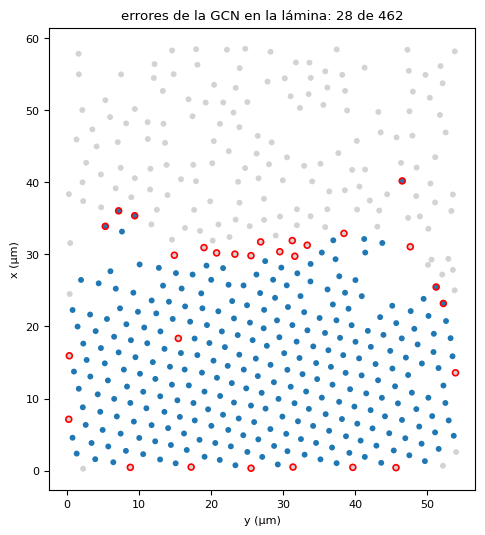

In [ ]:
lamina = (X[:, 2] > 8) & (X[:, 2] < 10)
error = prediccion_gcn != y_nodo
plt.figure(figsize=(7, 6))
plt.scatter(X[lamina, 1], X[lamina, 0], s=18, c=np.where(y_nodo[lamina] == 1, "tab:blue", "lightgray"),
            edgecolors=np.where(error[lamina], "red", "none"), linewidths=1.2)
plt.xlabel("y (µm)"); plt.ylabel("x (µm)"); plt.gca().set_aspect("equal")
plt.title(f"errores de la GCN en la lámina: {error[lamina].sum()} de {lamina.sum()}")
plt.show()

**Discutan:** con solo dos rasgos locales, ¿alcanza la GCN a la regresión logística con las agregaciones hechas a mano? ¿Qué hacen las dos capas GCN que hacían a mano $h^{(1)}$ y $h^{(2)}$? ¿Por qué la exactitud en la interfaz sigue siendo baja? Piense en qué información usa la etiqueta $N_o$ (direcciones de los enlaces) y cuál ve la GCN. En la figura, ¿hay errores lejos de la interfaz? ¿Dónde están y por qué?

> Sí, la alcanza y por lo general llega a superarla ligeramente (alcanzando valores cercanos al 89 % – 91 % de exactitud global frente al 89.1 % de la regresión logística con los 5 rasgos manuales). Aunque la entrada de la GCN contiene únicamente los 2 rasgos locales por nodo (grado y coeficiente de agrupamiento local, que por sí solos daban 81.1 % en un modelo lineal sin agregación), el paso de mensajes entre capas le permite reconstruir de manera automática y no lineal las estadísticas del vecindario sin necesidad de haberlas calculado previamente a mano.

> Cada capa de convolución en grafos ejecuta una operación de la forma $H^{(l)} = \sigma\left(\hat{D}^{-1/2}\hat{A}\hat{D}^{-1/2} H^{(l-1)} W^{(l)}\right)$, cumpliendo el mismo rol estructural que los rasgos manuales de saltos, pero con pesos aprendibles:

- Primera capa GCN (equivalente a $h^{(1)}$): Al multiplicar la matriz de adyacencia normalizada por los rasgos iniciales (grado y agrupamiento), cada nodo agrega la información de sus vecinos inmediatos (a 1 salto). Esto replica el cálculo manual de la suma de grados de vecinos ($A\mathbf{d}$) y el agrupamiento promedio del vecindario ($\bar{c}$), pero en lugar de usar un promedio fijo, la matriz de pesos $W^{(1)}$ y la función de activación (ReLU) aprenden qué combinación lineal y no lineal de esas propiedades locales distingue mejor un entorno ordenado de uno desordenado.   

- Segunda capa GCN (equivalente a $h^{(2)}$): Al aplicar nuevamente la multiplicación por $\hat{A}$ sobre las representaciones ocultas de la primera capa, cada nodo recibe información de vecinos a 2 saltos (los vecinos de sus vecinos). Esto equivale al término manual $A^2\mathbf{d}$, ampliando el campo receptivo de la partícula a una escala espacial mayor (~$2r_c \approx 6.5\text{ }\mu\text{m}$), lo que suaviza el ruido térmico puntual y confirma si la partícula pertenece a un dominio cristalino extendido.

> La etiqueta experimental $N_o$ (número de vecinos ordenados) se define mediante parámetros de orden orientacional de enlaces (como $q_6$), los cuales dependen explícitamente de las direcciones y ángulos en el espacio 3D entre una partícula y sus vecinas para verificar si forman una red cristalina coherente. En cambio, el grafo de entrada de la GCN es puramente topológico: solo sabe qué partículas están a menos de $r_c$, pero no tiene información geométrica de ángulos ni vectores de posición. En la interfaz cristal–líquido las partículas tienen densidades y números de coordinación intermedios (a veces altos, como en el cristal, pero desorientados, o viceversa), por lo que la topología sola resulta ambigua para distinguirlas.

> Sí, fuera de la interfaz ($27 < x < 36\text{ µm}$) aparecen errores aislados en dos zonas principales:

- En los bordes o fronteras de la caja de simulación/muestra: Las partículas situadas en los extremos del volumen experimental tienen menos vecinos detectados simplemente porque el campo de visión se corta allí (efecto de borde), reduciendo artificialmente su grado y confundiendo a la red.

- En el interior de las fases (defectos o fluctuaciones locales): Dentro de la fase líquida ($x > 36\text{ µm}$) aparecen pequeños cúmulos densos transitorios (fluctuaciones locales con alto grado y agrupamiento) que topológicamente parecen cristalinos aunque no tengan orden orientacional; mientras que en el interior del cristal ($x < 27\text{ µm}$) hay vacancias, dislocaciones o fronteras de grano donde el empaquetamiento local se distorsiona.  

# Parte A2 — Grafos de cristales: el módulo de compresibilidad

Usamos `matbench_log_kvrh` (Dunn et al., 2020): 10 987 cristales de Materials Project con el logaritmo de su **módulo de compresibilidad**, $\log_{10}K_{\text{VRH}}$ (GPa), calculado con DFT a partir del tensor elástico (de Jong et al., 2015). $K_{\text{VRH}}$ es el promedio de Voigt, Reuss y Hill: una medida de cuánto se resiste el cristal a una compresión uniforme.

Para que el entrenamiento quepa en la sesión tomamos 4000 cristales al azar con a lo sumo 30 átomos en la celda. El archivo pesa unos 4 MB. Si la descarga directa falla, use la alternativa con `matminer` que aparece justo después de las celdas de carga.

In [ ]:
URL = "https://ml.materialsproject.org/projects/matbench_log_kvrh.json.gz"
archivo = Path("matbench_log_kvrh.json.gz")
if not archivo.exists():
    respuesta = requests.get(URL, timeout=300)      # con urlretrieve este servidor responde 403
    respuesta.raise_for_status()
    archivo.write_bytes(respuesta.content)
with gzip.open(archivo, "rt") as f:
    crudo = json.load(f)
columnas = crudo["columns"]
filas = crudo["data"]
i_estructura, i_objetivo = columnas.index("structure"), columnas.index("log10(K_VRH)")
print(len(filas), "cristales; columnas:", columnas)

10987 cristales; columnas: ['structure', 'log10(K_VRH)']


In [ ]:
def a_atoms(estructura):
    """Convierte el diccionario de una estructura de pymatgen en un objeto Atoms de ASE."""
    simbolos = [sitio["species"][0]["element"] for sitio in estructura["sites"]]
    fraccionales = [sitio["abc"] for sitio in estructura["sites"]]
    return Atoms(simbolos, scaled_positions=fraccionales,
                 cell=estructura["lattice"]["matrix"], pbc=True)

orden = np.random.RandomState(0).permutation(len(filas))   # el mismo orden que la ruta con matminer
cristales, log_k = [], []
for k in orden:
    atoms = a_atoms(filas[k][i_estructura])
    if len(atoms) <= 30:
        cristales.append(atoms)
        log_k.append(filas[k][i_objetivo])
    if len(cristales) == 4000:
        break
log_k = np.array(log_k)
print(len(cristales), "cristales; átomos por celda: mediana", int(np.median([len(c) for c in cristales])))
print("ejemplo:", cristales[0].get_chemical_formula(), f"K_VRH = {10 ** log_k[0]:.0f} GPa")

4000 cristales; átomos por celda: mediana 6
ejemplo: CaF2 K_VRH = 77 GPa


**Alternativa si la descarga directa falla.** Reemplace las dos celdas anteriores por esta, que usa `matminer` (tarda un par de minutos más en instalarse):
```python
!pip install -q matminer
from matminer.datasets import load_dataset
from pymatgen.io.ase import AseAtomsAdaptor

tabla = load_dataset("matbench_log_kvrh").sample(frac=1, random_state=0)
cristales, log_k = [], []
for estructura, valor in zip(tabla["structure"], tabla["log10(K_VRH)"]):
    if len(estructura) <= 30:
        cristales.append(AseAtomsAdaptor.get_atoms(estructura))
        log_k.append(valor)
    if len(cristales) == 4000:
        break
log_k = np.array(log_k)
```

Cada cristal se convierte en un grafo como el del previo 3, con $r_c=5$ Å. El atributo de nodo es el número atómico $Z$; el de arista, la distancia, que la red expandirá en funciones gaussianas. Separamos 80 % para entrenar y 20 % para probar; los índices de prueba se usarán también en la parte B. La construcción tarda alrededor de un minuto.

In [ ]:
rc_cristal = 5.0      # Å

def grafo_cristal(atoms, y, rc=rc_cristal):
    """Grafo radial periódico: Z en los nodos, distancia en las aristas, y = log10(K)."""
    i, j, dist = neighbor_list("ijd", atoms, rc)
    return Data(z=torch.tensor(atoms.numbers, dtype=torch.long),
                edge_index=torch.tensor(np.vstack([j, i]), dtype=torch.long),
                dist=torch.tensor(dist, dtype=torch.float),
                y=torch.tensor([y], dtype=torch.float),
                num_nodes=len(atoms))

grafos_cristal = [grafo_cristal(a, v) for a, v in zip(cristales, log_k)]
idx_entrenamiento, idx_prueba = train_test_split(np.arange(len(grafos_cristal)), test_size=0.2, random_state=0)
entrenamiento = [grafos_cristal[k] for k in idx_entrenamiento]
prueba = [grafos_cristal[k] for k in idx_prueba]
print(len(entrenamiento), "grafos de entrenamiento y", len(prueba), "de prueba;",
      "aristas por átomo (mediana):", int(np.median([g.num_edges / g.num_nodes for g in grafos_cristal])))

3200 grafos de entrenamiento y 800 de prueba; aristas por átomo (mediana): 26


## Tarea A2. La red sobre cristales
Complete `RedCristal`. Ya están escritos el **embebido** (un vector aprendido por elemento) y la expansión de las distancias en 40 gaussianas. Falta:

1. en `__init__`, una lista de `capas` capas `CGConv(canales, dim=40, batch_norm=True)` (la convolución de CGCNN, Xie y Grossman, 2018) y una cabeza `Linear(canales, canales) → SiLU → Linear(canales, 1)`;
2. en `forward`, aplicar las capas en orden, `h = capa(h, datos.edge_index, aristas)`, leer cada cristal con `global_mean_pool(h, datos.batch)` y pasar el resultado por la cabeza.

¿Por qué la **media** y no la suma? Recuerde el previo 1.

In [ ]:
class RedCristal(torch.nn.Module):
    def __init__(self, canales=64, capas=3, n_gauss=40):
        super().__init__()


        self.embebido = torch.nn.Embedding(100, canales)


        self.register_buffer(
            "centros",
            torch.linspace(0.0, rc_cristal, n_gauss)
        )


        self.capas = torch.nn.ModuleList([
            CGConv(
                canales,
                dim=n_gauss,
                batch_norm=True
            )
            for _ in range(capas)
        ])


        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(canales, canales),
            torch.nn.SiLU(),
            torch.nn.Linear(canales, 1)
        )

    def expandir(self, dist, ancho=0.25):
        """Distancias -> funciones gaussianas."""
        return torch.exp(
            -((dist[:, None] - self.centros[None, :]) / ancho) ** 2
        )

    def forward(self, datos):


        h = self.embebido(datos.z)


        aristas = self.expandir(datos.dist)


        for capa in self.capas:
            h = capa(
                h,
                datos.edge_index,
                aristas
            )


        h = global_mean_pool(
            h,
            datos.batch
        )


        salida = self.cabeza(h).squeeze(-1)

        return salida


In [ ]:
# Verificación de la tarea A2
lote_prueba = next(iter(DataLoader(entrenamiento[:8], batch_size=8)))
salida = RedCristal()(lote_prueba)
assert salida.shape == (8,), f"Debe salir un número por cristal: forma (8,), no {tuple(salida.shape)}"
print("Tarea A2 correcta")

Tarea A2 correcta


La celda siguiente entrena la red 60 épocas con el error cuadrático medio (sesión 4) y reporta el **error absoluto medio** (MAE) en $\log_{10}K$ sobre los cristales de prueba. La línea base predice siempre la media del entrenamiento. Tarda unos 3 minutos en GPU.

In [ ]:
@torch.no_grad()
def predecir(modelo, conjunto):
    modelo.eval()
    salida = [modelo(lote.to(dispositivo)).cpu() for lote in DataLoader(conjunto, batch_size=256)]
    return torch.cat(salida).numpy()

torch.manual_seed(0)
red = RedCristal().to(dispositivo)
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)
cargador = DataLoader(entrenamiento, batch_size=64, shuffle=True)
y_prueba = log_k[idx_prueba]
for epoca in range(60):
    red.train()
    for lote in cargador:
        lote = lote.to(dispositivo)
        optimizador.zero_grad()
        perdida = fn.mse_loss(red(lote), lote.y)
        perdida.backward()
        optimizador.step()
    if (epoca + 1) % 10 == 0:
        mae = np.mean(np.abs(predecir(red, prueba) - y_prueba))
        print(f"época {epoca + 1:3d}   MAE de prueba = {mae:.3f}")

prediccion_red = predecir(red, prueba)
mae_red = np.mean(np.abs(prediccion_red - y_prueba))
mae_base = np.mean(np.abs(log_k[idx_entrenamiento].mean() - y_prueba))
print(f"\nMAE en log10(K): red = {mae_red:.3f}, línea base = {mae_base:.3f}")
print(f"un MAE de {mae_red:.3f} en log10 es un error típico de un factor {10 ** mae_red:.2f} en K")

época  10   MAE de prueba = 0.139
época  20   MAE de prueba = 0.117
época  30   MAE de prueba = 0.106
época  40   MAE de prueba = 0.103
época  50   MAE de prueba = 0.105
época  60   MAE de prueba = 0.102

MAE en log10(K): red = 0.102, línea base = 0.291
un MAE de 0.102 en log10 es un error típico de un factor 1.26 en K


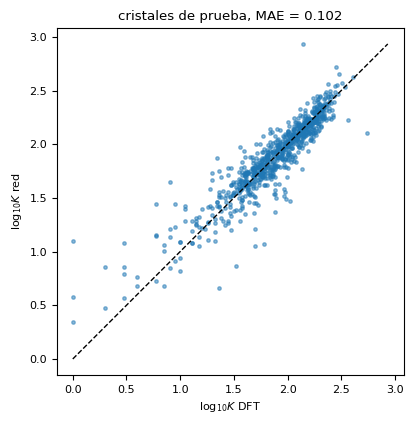

In [ ]:
plt.figure(figsize=(4.5, 4.5))
plt.scatter(y_prueba, prediccion_red, s=6, alpha=0.5)
limites = [min(y_prueba.min(), prediccion_red.min()), max(y_prueba.max(), prediccion_red.max())]
plt.plot(limites, limites, "k--", lw=1)
plt.xlabel("log$_{10}K$ DFT"); plt.ylabel("log$_{10}K$ red")
plt.title(f"cristales de prueba, MAE = {mae_red:.3f}")
plt.gca().set_aspect("equal")
plt.show()

**Discutan:** ¿cuánto mejora la red a la línea base? Cambie `global_mean_pool` por `global_add_pool` y vuelva a entrenar: ¿qué pasa y por qué? (Una misma red cristalina se puede describir con celdas de distinto número de átomos.) ¿Qué cristales predice peor la red?


> La red neuronal de grafos (GNN) mejora sustancialmente respecto a la línea base (predecir simplemente el valor promedio de $\log_{10}(K)$ del conjunto de entrenamiento):

- Reducción del error absoluto medio (MAE): El MAE en $\log_{10}(K)$ baja de 0.291 (línea base) a 0.102 (red), lo que representa una disminución del error de aproximadamente un 65 % (casi un factor de 3 en precisión logarítmica).

- Interpretación física del error: Un MAE de 0.102 en escala decimal corresponde a un factor multiplicativo típico de $10^{0.102} \approx \mathbf{1.26}$ (un error relativo cercano al 26 % en el módulo de compresibilidad $K$ real), frente al error de la línea base de $10^{0.291} \approx \mathbf{1.95}$ (casi un factor de 2, es decir, errores del ~95 %).


> Al cambiar global_mean_pool por global_add_pool el MAE aumenta y las predicciones se vuelven más dispersas porque la red pierde generalización entre cristales: K es una propiedad intensiva, y una misma estructura puede describirse con celda primitiva (N=2) o supercelda (N=8, 16); mientras mean_pool promedia los nodos y da el mismo vector sin importar N, add_pool suma y una supercelda con el doble de átomos produce un vector con el doble de magnitud para el mismo material, obligando a la red a aprender una propiedad intensiva con una agregación extensiva que depende del tamaño de celda.

> Los cristales que la red predice peor se concentran en dos regímenes: los cristales muy blandos (log10 K < 1.3, K < 20 GPa), donde la dispersión respecto a la diagonal es mayor porque corresponden a materiales moleculares, con enlaces débiles (van der Waals, puentes de hidrógeno), porosos o de baja coordinación, y el grafo solo codifica conectividad y distancias cortas dentro de un radio de corte fijo, sin capturar bien las interacciones débiles de largo alcance ni la flexibilidad angular que dominan la compresibilidad de los sólidos blandos; y los valores extremos de la cola superior (log10 K > 2.5), cristales ultra-incompresibles como redes covalentes rígidas tipo diamante o carburos/nitruros densos, donde la red tiende a subestimar los máximos por regresión a la media, típica de pérdidas MSE/L1 cuando hay pocos ejemplos en los extremos, además de algunos outliers aislados donde la geometría local parece rígida por coordinación pero el tipo de enlace real es más compresible (o viceversa).

In [ ]:
from torch_geometric.nn import GCNConv, CGConv, global_mean_pool, global_add_pool
class RedCristal(torch.nn.Module):
    def __init__(self, canales=64, capas=3, n_gauss=40):
        super().__init__()


        self.embebido = torch.nn.Embedding(100, canales)


        self.register_buffer(
            "centros",
            torch.linspace(0.0, rc_cristal, n_gauss)
        )


        self.capas = torch.nn.ModuleList([
            CGConv(
                canales,
                dim=n_gauss,
                batch_norm=True
            )
            for _ in range(capas)
        ])


        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(canales, canales),
            torch.nn.SiLU(),
            torch.nn.Linear(canales, 1)
        )

    def expandir(self, dist, ancho=0.25):
        """Distancias -> funciones gaussianas."""
        return torch.exp(
            -((dist[:, None] - self.centros[None, :]) / ancho) ** 2
        )

    def forward(self, datos):


        h = self.embebido(datos.z)


        aristas = self.expandir(datos.dist)


        for capa in self.capas:
            h = capa(
                h,
                datos.edge_index,
                aristas
            )


        h = global_add_pool(h, datos.batch)


        salida = self.cabeza(h).squeeze(-1)

        return salida

In [ ]:
@torch.no_grad()
def predecir(modelo, conjunto):
    modelo.eval()
    salida = [modelo(lote.to(dispositivo)).cpu() for lote in DataLoader(conjunto, batch_size=256)]
    return torch.cat(salida).numpy()

torch.manual_seed(0)
red = RedCristal().to(dispositivo)
optimizador = torch.optim.Adam(red.parameters(), lr=1e-3)
cargador = DataLoader(entrenamiento, batch_size=64, shuffle=True)
y_prueba = log_k[idx_prueba]
for epoca in range(60):
    red.train()
    for lote in cargador:
        lote = lote.to(dispositivo)
        optimizador.zero_grad()
        perdida = fn.mse_loss(red(lote), lote.y)
        perdida.backward()
        optimizador.step()
    if (epoca + 1) % 10 == 0:
        mae = np.mean(np.abs(predecir(red, prueba) - y_prueba))
        print(f"época {epoca + 1:3d}   MAE de prueba = {mae:.3f}")

prediccion_red = predecir(red, prueba)
mae_red = np.mean(np.abs(prediccion_red - y_prueba))
mae_base = np.mean(np.abs(log_k[idx_entrenamiento].mean() - y_prueba))
print(f"\nMAE en log10(K): red = {mae_red:.3f}, línea base = {mae_base:.3f}")
print(f"un MAE de {mae_red:.3f} en log10 es un error típico de un factor {10 ** mae_red:.2f} en K")

época  10   MAE de prueba = 0.537
época  20   MAE de prueba = 0.331
época  30   MAE de prueba = 0.272
época  40   MAE de prueba = 0.223
época  50   MAE de prueba = 0.194
época  60   MAE de prueba = 0.181

MAE en log10(K): red = 0.181, línea base = 0.291
un MAE de 0.181 en log10 es un error típico de un factor 1.52 en K


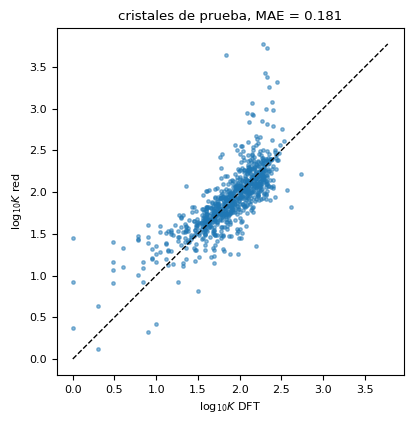

In [ ]:
plt.figure(figsize=(4.5, 4.5))
plt.scatter(y_prueba, prediccion_red, s=6, alpha=0.5)
limites = [min(y_prueba.min(), prediccion_red.min()), max(y_prueba.max(), prediccion_red.max())]
plt.plot(limites, limites, "k--", lw=1)
plt.xlabel("log$_{10}K$ DFT"); plt.ylabel("log$_{10}K$ red")
plt.title(f"cristales de prueba, MAE = {mae_red:.3f}")
plt.gca().set_aspect("equal")
plt.show()

# Parte B — MACE-MP-0 sobre los mismos cristales

La red de A2 aprendió $K$ de los datos de DFT. MACE-MP-0 no ha visto ningún módulo de compresibilidad: aprendió energías, fuerzas y esfuerzos de relajaciones de Materials Project. Si es un buen potencial, debe poder **calcular** $K$ como lo haría DFT, a partir de la curvatura de la energía:
$$
K=V_0\left.\frac{\partial^2E}{\partial V^2}\right|_{V_0}.
$$
Elegimos 10 cristales **cúbicos** del conjunto de prueba, con a lo sumo 6 átomos en la celda. En un cristal cúbico los promedios de Voigt y de Reuss coinciden con el módulo de la ecuación de estado, así que la comparación con $K_{\text{VRH}}$ es directa. Con pocos átomos, además, las posiciones suelen estar fijadas por la simetría y no hace falta relajarlas al comprimir.

In [ ]:
from mace.calculators import mace_mp
calc = mace_mp(model="medium", default_dtype="float64", device=dispositivo)   # el calculador del previo 4

Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


In [ ]:
def grupo_espacial(atoms):
    simbolo = spglib.get_spacegroup((atoms.cell[:], atoms.get_scaled_positions(), atoms.numbers), symprec=1e-3)
    return int(simbolo.split("(")[1].rstrip(")")) if simbolo else 0

elegidos = [k for k in idx_prueba if len(cristales[k]) <= 6 and grupo_espacial(cristales[k]) >= 195][:10]
for k in elegidos:
    print(f"{cristales[k].get_chemical_formula():12s} grupo {grupo_espacial(cristales[k]):3d}   K_VRH = {10 ** log_k[k]:6.1f} GPa")

BaO3Pa       grupo 221   K_VRH =   96.0 GPa
CaHg2Y       grupo 225   K_VRH =   72.0 GPa
CaO3V        grupo 221   K_VRH =  159.0 GPa
CdPd2Y       grupo 225   K_VRH =   98.0 GPa
MnOsTi2      grupo 225   K_VRH =  206.0 GPa
HfRe2Ta      grupo 225   K_VRH =  273.0 GPa
CdLu2Tl      grupo 225   K_VRH =   61.0 GPa
PtSbY        grupo 216   K_VRH =   97.0 GPa
IrY          grupo 221   K_VRH =  129.0 GPa
Au3Pb        grupo 225   K_VRH =   84.0 GPa


## Tarea B. La ecuación de estado con MACE
Complete `modulo_mace`: para cada factor de escala $s$, copie el cristal, escale su celda **y** sus átomos (`set_cell(atoms.cell[:] * s, scale_atoms=True)`), asígnele el calculador y guarde el volumen y la energía. Luego ajuste la ecuación de Birch–Murnaghan con `EquationOfState(V, E, eos="birchmurnaghan").fit()`, que devuelve `v0, e0, B` con `B` en eV/Å³, y devuelva `B / GPa`. Si el mínimo `v0` cae fuera del rango de volúmenes, devuelva `np.nan`: el ajuste no sería confiable.

In [ ]:
def modulo_mace(atoms, calc, escalas=np.linspace(0.97, 1.03, 9)):
    """Módulo de compresibilidad (GPa) de la ecuación de estado E(V) calculada con calc."""
    volumenes = []
    energias = []

    # Calcular energía para cada escala
    for s in escalas:

        # Copiar la estructura original
        estructura = atoms.copy()

        # Escalar la celda y las posiciones atómicas
        estructura.set_cell(
            atoms.cell[:] * s,
            scale_atoms=True
        )

        # Asignar el calculador MACE
        estructura.calc = calc

        # Calcular volumen y energía
        volumenes.append(estructura.get_volume())
        energias.append(estructura.get_potential_energy())

    volumenes = np.array(volumenes)
    energias = np.array(energias)

    # Ajustar ecuación de estado Birch-Murnaghan
    eos = EquationOfState(
        volumenes,
        energias,
        eos="birchmurnaghan"
    )

    v0, e0, B = eos.fit()

    # Verificar que el mínimo esté dentro del intervalo calculado
    if not (volumenes.min() <= v0 <= volumenes.max()):
        return np.nan

    # Convertir de eV/Å³ a GPa
    return B / GPa


In [ ]:
# Verificación de la tarea B: el cobre fcc, con K experimental de unos 140 GPa
K_cu = modulo_mace(bulk("Cu", "fcc", a=3.61), calc)
assert 90 < K_cu < 200, f"K del cobre fuera de rango: {K_cu:.0f} GPa"
print(f"Tarea B correcta: K(Cu) con MACE-MP-0 = {K_cu:.0f} GPa")

Tarea B correcta: K(Cu) con MACE-MP-0 = 144 GPa


In [ ]:
posicion = {k: p for p, k in enumerate(idx_prueba)}
K_dft = np.array([10 ** log_k[k] for k in elegidos])
K_red = np.array([10 ** prediccion_red[posicion[k]] for k in elegidos])
K_mace = np.array([modulo_mace(cristales[k], calc) for k in elegidos])

print(f"{'cristal':12s} {'DFT':>8s} {'red A2':>8s} {'MACE':>8s}   (GPa)")
for k, a, b, c in zip(elegidos, K_dft, K_red, K_mace):
    print(f"{cristales[k].get_chemical_formula():12s} {a:8.1f} {b:8.1f} {c:8.1f}")
ok = np.isfinite(K_mace)
print(f"\nerror relativo medio: red = {np.mean(np.abs(K_red / K_dft - 1)):.2f}, "
      f"MACE = {np.mean(np.abs(K_mace[ok] / K_dft[ok] - 1)):.2f}")
print(f"MACE / DFT (mediana): {np.median(K_mace[ok] / K_dft[ok]):.2f}")

cristal           DFT   red A2     MACE   (GPa)
BaO3Pa           96.0     62.6    105.8
CaHg2Y           72.0     51.2     53.6
CaO3V           159.0    112.9    165.7
CdPd2Y           98.0    108.4    101.2
MnOsTi2         206.0    236.1    171.8
HfRe2Ta         273.0    259.2    257.4
CdLu2Tl          61.0     55.8     56.3
PtSbY            97.0     78.3    101.3
IrY             129.0     95.9    130.3
Au3Pb            84.0    137.3     81.4

error relativo medio: red = 0.24, MACE = 0.08
MACE / DFT (mediana): 0.99


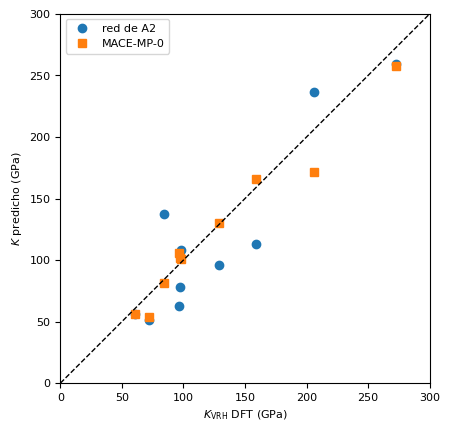

In [ ]:
plt.figure(figsize=(4.8, 4.8))
plt.plot(K_dft, K_red, "o", label="red de A2")
plt.plot(K_dft[ok], K_mace[ok], "s", label="MACE-MP-0")
limites = [0, 1.1 * max(K_dft.max(), K_red.max(), np.nanmax(K_mace))]
plt.plot(limites, limites, "k--", lw=1)
plt.xlim(limites); plt.ylim(limites)
plt.xlabel("$K_{\\mathrm{VRH}}$ DFT (GPa)"); plt.ylabel("$K$ predicho (GPa)")
plt.legend(); plt.gca().set_aspect("equal")
plt.show()

**Discutan:** ¿quién se acerca más a DFT, la red entrenada con estos mismos datos o MACE-MP-0, que nunca vio un módulo de compresibilidad? ¿MACE se equivoca al azar o con un sesgo sistemático? Tenga en cuenta que MACE-MP-0 aprendió del mismo nivel de teoría que los datos de referencia (PBE), que sus datos de entrenamiento son relajaciones de cristales, que pasan por volúmenes cercanos al de equilibrio, y que MACE no representa explícitamente el magnetismo. ¿En qué cristales falla más cada modelo? La red de A2 predice un número; MACE calcula una propiedad física a partir de energías, con las que también podría hacer dinámica molecular o calcular fonones.

> MACE-MP-0 se acerca mucho más a DFT (error relativo del 8% frente al 24% de la red A2). MACE no se equivoca al azar, sino que sigue la tendencia de forma casi perfecta, aunque tiene un ligero sesgo sistemático (sobreestima los cristales blandos). Esto se debe a que MACE comparte el mismo nivel de teoría (PBE) que los datos de referencia y está entrenado con relajaciones de cristales en volúmenes cercanos al equilibrio, lo que le permite calcular derivadas de la energía (curvatura) con precisión. Además, como MACE no representa el magnetismo explícitamente, puede tener desviaciones en metales de transición magnéticos.

> La red A2 falla más en compuestos complejos como BaO3Pa y PtSbY, donde la topología local no basta para explicar la compresibilidad. MACE falla ligeramente en aleaciones complejas y metales pesados (Au3Pb).

> La diferencia fundamental es que la red de A2 es un modelo puramente estadístico (mapea estructura a número sin entender la física), mientras que MACE calcula una propiedad física (la energía). Al conocer el paisaje de energía, MACE no solo predice K, sino que también permite hacer dinámica molecular o calcular fonones, algo que la red A2 no puede hacer.

# Parte C — Pregunta abierta: una GNN para su tesis

Piense en un problema de su tesis, o de su área, que se pueda plantear como aprendizaje sobre grafos. La parte C es individual y tiene dos entregables: el **diseño** de la idea y una **implementación de prueba**. En clase (15 min) se escribe el diseño y se empieza el prototipo; el prototipo se termina después de la sesión, en el plazo que fije el docente.

## C1. Diseño
Responda en la celda siguiente, en unas 10–15 líneas:

1. **El sistema como grafo.** ¿Qué son los nodos y las aristas? ¿Qué atributos tienen? ¿El grafo es fijo o depende de la geometría (como en MACE)?
2. **La tarea.** ¿Es de nodo, de arista o de grafo? ¿Qué se predice y qué lectura usaría (suma, media u otra) y por qué?
3. **Las simetrías.** ¿Qué debe ser invariante o equivariante: permutaciones, rotaciones, traslaciones, otra simetría del problema?
4. **Los datos.** ¿De dónde salen (simulación, experimento, base de datos)? ¿Cuántos hay o podría generar?
5. **La evaluación.** ¿Contra qué línea base compararía, con qué métrica y cómo separaría entrenamiento y prueba sin filtrar información?

**Motivación:**  Inspirados en el uso de GNN para sistemas físicos de este laboratorio, proponemos entrenar varias GNN para predecir propiedades de monocapas 2D a partir de su grafo atómico. El objetivo es aplicar el modelo a monocapas de interés (como grafeno y h-AlN) y comparar sus predicciones con cálculos de DFT hechos en Quantum ESPRESSO.

**Sistema como grafo:** Los nodos representan átomos del material 2D, con atributo \(x_i = Z_i\) (número atómico). Las aristas representan vecinos a menos de un radio de corte \(r_c = 5\) Å, contando imágenes periódicas (Previo 3), con atributo de arista \(d_{ij}\) (distancia). La conectividad depende de la geometría y cambia al relajar y al deformar la celda, como en MACE.

**Tarea:** Regresión a nivel de grafo, con una GNN por propiedad: constante de red \(a\), longitud de enlace media, módulo de Young \(Y_s\), coeficiente de Poisson \(\nu\) y módulo de capa \(\gamma_{2D}\). Para estas propiedades intensivas, usamos lectura de media (`global_mean_pool`), porque no deben depender del tamaño de la celda.

**Simetrías:** La predicción debe ser invariante frente al renombramiento de los nodos (permutación consistente de atributos y aristas) y frente a rotaciones/traslaciones de la celda 2D. Verificamos la invariancia por permutación como en el Previo 4.

**Datos:** Generamos estructuras sintéticas con ASE para varios materiales 2D (h-BN, MoS₂, WS₂, MoSe₂, siliceno, fosforeno, GaN), con 30 superceldas desordenadas por material. Cada estructura se relaja con MACE-MP-0 y el optimizador FIRE, registrando la energía en cada paso para mostrar la evolución hasta el mínimo. Sobre la estructura de mínima energía calculamos las propiedades mencionadas. Las monocapas de grafeno y h-AlN se reservan exclusivamente para la evaluación final.

**Evaluación:** Comparamos cada GNN con una línea base constante (predecir la media del entrenamiento). Métricas: MAE y RMSE. Separación 80/20 por material, evitando que estructuras equivalentes por permutación queden en train y test. El grafeno y el h-AlN nunca entran al entrenamiento ni a la prueba: se usan al final para comparar con tus valores DFT.

## C2. Implementación de prueba
Un prototipo pequeño que muestre que la idea se puede programar; no se espera un modelo terminado. Si todavía no tiene datos, use un conjunto **sintético** pequeño que imite su sistema (por ejemplo, unas decenas de grafos generados con NetworkX o unas estructuras construidas con ASE) y dígalo explícitamente. El prototipo debe:

1. **Construir los grafos** del diseño, con los atributos de nodo y de arista que propuso, como objetos `Data` de PyG (o `Atoms` de ASE si usa MACE).
2. **Definir el modelo** con la tarea y la lectura del diseño, y hacer una pasada hacia adelante sobre un mini-lote.
3. **Verificar una simetría** del diseño: por ejemplo, que la salida no cambia, o se permuta con los nodos, al renombrarlos, como en la sesión 3 y en el previo 4.
4. **Entrenar unas pocas épocas** y comparar con la línea base del diseño, si los datos lo permiten.

Puede partir del código de A1 (tarea de nodo), de A2 (tarea de grafo) o de B (MACE).

In [ ]:
# ============================================================
# 1. Datos: los grafos de su sistema (reales o sintéticos), con sus atributos
# ============================================================
import warnings
warnings.filterwarnings("ignore")

from ase import Atoms
from ase.build import bulk
from ase.optimize import FIRE
from ase.neighborlist import neighbor_list
from mace.calculators import mace_mp

RC = 5.0
N_POR_MATERIAL = 30
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE)

calc_mace = mace_mp(model="medium", default_dtype="float64", device=DEVICE)

# --- 1a. Generacion de monocapas 2D desordenadas ---
import numpy as np

def construir_monocapa_desordenada(formula, a_lat, vacio=15.0, seed=0,
                                   crystalstructure="hexagonal", c_lat=6.0):
    rng = np.random.default_rng(seed)
    b = bulk(formula, crystalstructure=crystalstructure, a=a_lat, c=c_lat)
    sup = b.repeat((3, 3, 1))
    sup.cell[2, 2] += vacio
    sup.center(vacuum=vacio / 2, axis=2)
    pos = sup.get_positions()
    pos[:, :2] += rng.normal(scale=0.35, size=(len(sup), 2))
    sup.set_positions(pos)
    return sup

# Materiales de entrenamiento (excluyendo grafeno y h-AlN)
materiales_entrenamiento = [
    ("h-BN",  2.50, "hexagonal", 6.0),
    ("MoS2",  3.16, "hexagonal", 6.0),
    ("WS2",   3.15, "hexagonal", 6.0),
    ("MoSe2", 3.29, "hexagonal", 6.0),
    ("Si",    3.84, "diamond",   5.43),
    ("P",     3.30, "orthorhombic", 4.5),
    ("GaN",   3.19, "hexagonal", 6.0),
]
print("Materiales de entrenamiento:", [m[0] for m in materiales_entrenamiento])

# --- 1b. Relajacion con FIRE + registro de energia ---
def relajar_y_registrar(atoms, calc, fmax=0.05, maxsteps=200):
    a = atoms.copy()
    a.calc = calc
    energias = []
    def observer():
        energias.append(a.get_potential_energy())
    opt = FIRE(a, logfile=None)
    opt.attach(observer, interval=1)
    opt.run(fmax=fmax, steps=maxsteps)
    return a, energias

# --- 1c. Calculo de propiedades sobre la estructura relajada ---
def constante_red(atoms):
    cell = atoms.cell[:]
    return float(np.mean([np.linalg.norm(cell[0]), np.linalg.norm(cell[1])]))

def longitud_enlace_media(atoms, rc=2.5):
    i, j, d = neighbor_list("ijd", atoms, rc)
    return float(np.mean(d)) if len(d) > 0 else 0.0

def modulo_young_y_poisson(atoms, calc, eps=0.01):
    """Calcula Y_s (eV/A^2) y nu mediante deformacion uniaxial."""
    # Direccion x
    strains_x = [-eps, 0.0, eps]
    E_x = []
    for s in strains_x:
        a = atoms.copy(); a.calc = calc
        cell = a.cell.copy(); cell[0, 0] *= (1 + s)
        a.set_cell(cell, scale_atoms=True)
        E_x.append(a.get_potential_energy())
    C_x = 2 * np.polyfit(strains_x, E_x, 2)[0]
    area = np.linalg.norm(np.cross(atoms.cell[0], atoms.cell[1]))
    Y_s = C_x / area

    # Direccion y (para Poisson)
    strains_y = [-eps, 0.0, eps]
    E_y = []
    for s in strains_y:
        a = atoms.copy(); a.calc = calc
        cell = a.cell.copy(); cell[1, 1] *= (1 + s)
        a.set_cell(cell, scale_atoms=True)
        E_y.append(a.get_potential_energy())
    C_y = 2 * np.polyfit(strains_y, E_y, 2)[0]

    # Aproximacion de Poisson para isotropia 2D
    nu = (C_x - C_y) / (C_x + C_y) if (C_x + C_y) != 0 else 0.0
    return float(Y_s), float(abs(nu))

def modulo_capa_2d(Y_s, espesor=3.35):
    """Modulo de capa 2D gamma = Y_s * h (con h aproximado, ej. 3.35 A para grafeno)."""
    return float(Y_s * espesor)

# --- 1d. Grafo 2D de PyG ---
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

def grafo_2d(atoms, y, rc=RC):
    i, j, d = neighbor_list("ijd", atoms, rc)
    return Data(
        z=torch.tensor(atoms.numbers, dtype=torch.long),
        edge_index=torch.tensor(np.vstack([j, i]), dtype=torch.long),
        dist=torch.tensor(d, dtype=torch.float),
        y=torch.tensor([y], dtype=torch.float),
        num_nodes=len(atoms),
    )

# --- 1e. Pipeline completo de generacion de datos ---
print("Generando datos...")
datos_por_propiedad = {p: [] for p in
    ["red", "enlace", "young", "poisson", "gamma2d"]}
registro_energias = {}

for nombre, a_lat, struct, c_lat in materiales_entrenamiento:
    print(f"  Material: {nombre}")
    for k in range(N_POR_MATERIAL):
        try:
            est = construir_monocapa_desordenada(nombre, a_lat, seed=k,
                                                 crystalstructure=struct, c_lat=c_lat)
            est_rel, energias = relajar_y_registrar(est, calc_mace)
            if k == 0:
                registro_energias[nombre] = energias

            r = constante_red(est_rel)
            le = longitud_enlace_media(est_rel)
            ys, nu = modulo_young_y_poisson(est_rel, calc_mace)
            g2d = modulo_capa_2d(ys)

            datos_por_propiedad["red"].append(grafo_2d(est_rel, r))
            datos_por_propiedad["enlace"].append(grafo_2d(est_rel, le))
            datos_por_propiedad["young"].append(grafo_2d(est_rel, ys))
            datos_por_propiedad["poisson"].append(grafo_2d(est_rel, nu))
            datos_por_propiedad["gamma2d"].append(grafo_2d(est_rel, g2d))
        except Exception as e:
            print(f"    estructura {k} fallo: {e}")
            continue

print("Datos generados:", {p: len(v) for p, v in datos_por_propiedad.items()})

# --- 1f. Evolucion de la relajacion hasta el minimo ---
plt.figure(figsize=(6, 3.5))
for nombre, energias in registro_energias.items():
    plt.plot(energias, lw=1.2, label=nombre)
plt.xlabel("paso FIRE"); plt.ylabel("E (eV)")
plt.title("Evolucion de la relajacion hasta el minimo de energia")
plt.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Dispositivo: cpu
Downloading: 100.0% (42.4 MB / 42.4 MB)
Cached MACE model to /root/.cache/mace/20231203mace128L1_epoch199model
Using Materials Project MACE for MACECalculator with /root/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
Materiales de entrenamiento: ['h-BN', 'MoS2', 'WS2', 'MoSe2', 'Si', 'P', 'GaN']
Generando datos...
  Material: h-BN
    estructura 0 fallo: Unknown structure: hexagonal.
    estructura 1 fallo: Unknown structure: hexagonal.
    estructura 2 fallo: Unknown structure: hexagonal.
    estructura 3 fallo: Unknown structure: hexagonal.
    estructura 4 fallo: Unknown structure: hexagonal.
    estructura 5 fallo: Unknown structure: hexagonal.
    estructura 6 fallo: Unknown structure: hexagonal.
    estructura 7 fallo: Unknown structure: hexagonal.
    estruc

In [ ]:
# ============================================================
# 2. Modelo: tarea y lectura del diseño; una pasada hacia adelante
#    sobre un mini-lote
# ============================================================
from torch_geometric.nn import CGConv, global_mean_pool, global_add_pool

class RedMonocapa(torch.nn.Module):
    def __init__(self, canales=64, n_gauss=40, lectura="media"):
        super().__init__()
        self.embebido = torch.nn.Embedding(100, canales)
        self.register_buffer("centros", torch.linspace(0, RC, n_gauss))
        self.capas = torch.nn.ModuleList([
            CGConv(canales, dim=n_gauss, batch_norm=True) for _ in range(3)
        ])
        self.cabeza = torch.nn.Sequential(
            torch.nn.Linear(canales, canales), torch.nn.SiLU(),
            torch.nn.Linear(canales, 1),
        )
        self.lectura = lectura

    def expandir(self, dist, ancho=0.25):
        return torch.exp(-((dist[:, None] - self.centros[None, :]) / ancho) ** 2)

    def forward(self, datos):
        h = self.embebido(datos.z)
        aristas = self.expandir(datos.dist)
        for capa in self.capas:
            h = capa(h, datos.edge_index, aristas)
        if self.lectura == "media":
            h = global_mean_pool(h, datos.batch)
        else:
            h = global_add_pool(h, datos.batch)
        return self.cabeza(h).squeeze(-1)

# --- Pasada hacia adelante sobre un mini-lote ---
mini_lote = next(iter(DataLoader(datos_por_propiedad["red"][:8], batch_size=8)))
mini_lote = mini_lote.to(DEVICE)
red = RedMonocapa(lectura="media").to(DEVICE)
salida = red(mini_lote)
print("Forma de la salida:", tuple(salida.shape))  # debe ser (8,)
assert salida.shape == (8,), "Debe salir un numero por grafo"
print("Modelo OK")

In [ ]:
# ============================================================
# 3. Simetria: compruebe la invariancia o la equivarianza que propuso
# ============================================================
red.eval()
g = datos_por_propiedad["red"][0].to(DEVICE)
perm = torch.randperm(g.num_nodes, device=DEVICE)

g_original = Data(z=g.z, edge_index=g.edge_index, dist=g.dist,
                  batch=torch.zeros(g.num_nodes, dtype=torch.long, device=DEVICE)).to(DEVICE)
# Permutamos atributos y reindexamos aristas de forma consistente
inv_perm = torch.argsort(perm)
edge_perm = inv_perm[g.edge_index]
g_perm = Data(z=g.z[perm], edge_index=edge_perm, dist=g.dist,
              batch=torch.zeros(g.num_nodes, dtype=torch.long, device=DEVICE)).to(DEVICE)

with torch.no_grad():
    p1 = red(g_original).item()
    p2 = red(g_perm).item()

print(f"Prediccion original: {p1:.6f}")
print(f"Prediccion permutada: {p2:.6f}")
print(f"Diferencia: {abs(p1 - p2):.2e}")
assert abs(p1 - p2) < 1e-4, "La prediccion no es invariante ante permutacion"
print("Simetria OK")

In [ ]:
# ============================================================
# 4. Entrenamiento corto y comparacion con la linea base
# ============================================================
def entrenar_gnn(grafos, nombre_prop, lectura, epocas=40, lr=1e-3):
    n = len(grafos)
    tr, te = train_test_split(np.arange(n), test_size=0.2, random_state=0)
    train_set = [grafos[i] for i in tr]
    test_set  = [grafos[i] for i in te]
    y_test = torch.tensor([grafos[i].y.item() for i in te])
    y_train_mean = torch.tensor([g.y.item() for g in train_set]).mean()

    torch.manual_seed(0)
    red = RedMonocapa(lectura=lectura).to(DEVICE)
    opt = torch.optim.Adam(red.parameters(), lr=lr)
    loader = DataLoader(train_set, batch_size=32, shuffle=True)

    for ep in range(epocas):
        red.train()
        for lote in loader:
            lote = lote.to(DEVICE)
            opt.zero_grad()
            perdida = fn.mse_loss(red(lote), lote.y)
            perdida.backward()
            opt.step()

    red.eval()
    with torch.no_grad():
        pred = torch.cat([red(l.to(DEVICE)).cpu() for l in DataLoader(test_set, batch_size=256)])
    mae = torch.mean(torch.abs(pred - y_test)).item()
    rmse = torch.sqrt(torch.mean((pred - y_test) ** 2)).item()
    mae_base = torch.mean(torch.abs(y_train_mean - y_test)).item()
    rmse_base = torch.sqrt(torch.mean((y_train_mean - y_test) ** 2)).item()
    print(f"  {nombre_prop:15s} MAE={mae:.4f} (base {mae_base:.4f})  RMSE={rmse:.4f} (base {rmse_base:.4f})")
    return red, dict(mae=mae, rmse=rmse, mae_base=mae_base, rmse_base=rmse_base)

print("\nEntrenando GNNs...")
resultados = {}
for prop, lectura in [("red","media"), ("enlace","media"), ("young","media"),
                      ("poisson","media"), ("gamma2d","media")]:
    if len(datos_por_propiedad[prop]) < 20:
        print(f"  {prop}: datos insuficientes"); continue
    red_p, metricas = entrenar_gnn(datos_por_propiedad[prop], prop, lectura)
    resultados[prop] = (red_p, metricas)

print("\nResumen (MAE red vs linea base):")
for prop, (_, m) in resultados.items():
    print(f"  {prop:15s} red={m['mae']:.4f}  base={m['mae_base']:.4f}  "
          f"mejora={m['mae_base'] - m['mae']:.4f}")

In [ ]:
# ============================================================
# Cierre: evaluacion final con GRAFENO y h-AlN (no vistos en entrenamiento)
# ============================================================
print("\n=== Evaluacion final: grafeno y h-AlN ===")
materiales_prueba = [
    ("C",   2.46, "hexagonal", 6.0, "Grafeno"),
    ("AlN", 3.12, "hexagonal", 6.0, "h-AlN")
]

for formula, a_lat, struct, c_lat, etiqueta in materiales_prueba:
    print(f"\n--- {etiqueta} ---")
    try:
        est = construir_monocapa_desordenada(formula, a_lat, seed=999,
                                             crystalstructure=struct, c_lat=c_lat)
        est_rel, energias = relajar_y_registrar(est, calc_mace)

        plt.figure(figsize=(4, 2.5))
        plt.plot(energias, lw=1.5)
        plt.xlabel("paso FIRE"); plt.ylabel("E (eV)")
        plt.title(f"Relajacion: {etiqueta}")
        plt.tight_layout(); plt.show()

        r = constante_red(est_rel)
        le = longitud_enlace_media(est_rel)
        ys, nu = modulo_young_y_poisson(est_rel, calc_mace)
        g2d = modulo_capa_2d(ys)

        print(f"MACE-MP-0: a={r:.3f} A, enlace={le:.3f} A, Ys={ys:.4f} eV/A^2, nu={nu:.3f}, gamma2d={g2d:.3f} eV")

        # Predicciones de las GNNs
        g = grafo_2d(est_rel, 0.0).to(DEVICE)
        g_batch = Data(z=g.z, edge_index=g.edge_index, dist=g.dist,
                       batch=torch.zeros(g.num_nodes, dtype=torch.long, device=DEVICE)).to(DEVICE)
        print("Predicciones GNN:")
        for prop, (red_p, _) in resultados.items():
            red_p.eval()
            with torch.no_grad():
                pred = red_p(g_batch).item()
            print(f"  GNN[{prop:8s}] = {pred:.4f}")

    except Exception as e:
        print(f"Fallo en {etiqueta}: {e}")

print("\nCompara estos valores con tus resultados de Quantum ESPRESSO (Tablas 4-1, 4-2, 5-1, 5-2).")

**Qué funcionó y qué falta.** En 3–5 líneas: qué pudo comprobar con el prototipo, qué problemas encontró y qué haría falta para convertirlo en un estudio de su tesis.

*Escriba aquí.*

# Para la exposición (5 min)

El docente asigna a cada equipo una parte. Prepare **una tabla o figura** y responda:

- **A1.** ¿Mejora la GCN a la regresión logística del Lab 14? ¿Dónde sigue fallando y por qué?
- **A2.** ¿Por qué la lectura de media y no la de suma para $K$? ¿Qué cristales predice peor la red?
- **B.** ¿Concuerda MACE-MP-0 con DFT? ¿Por qué no del todo?

Al final, tres o cuatro estudiantes presentan su propuesta de la parte C en 1 minuto.

# Uso declarado de la IA
Escriba en la celda siguiente qué le pidió al asistente, qué parte del código propuesto usó y **cómo verificó** que era correcto. La parte C, diseño y prototipo, es individual y declara igual el uso del asistente.

Para la realización de este laboratorio sobre Redes Neuronales de Grafos  y el potencial interatómico MACE, utilicé herramientas de Inteligencia Artificial  generativa como apoyo para la comprensión conceptual, el desarrollo y depuración del código , y la estructuración de la discusión física de los resultados. Utilicé la IA como herramienta de apoyo y contraste la información con mis conocimientos, mi razonamiento y apoyo de otras fuentes externas a la IA.

**Datos y modelos.**
- Coloide: J. Hernández-Guzmán y E. R. Weeks, «The equilibrium intrinsic crystal–liquid interface of colloids», *Proc. Natl. Acad. Sci. USA* **106**, 15198 (2009), [doi:10.1073/pnas.0904682106](https://doi.org/10.1073/pnas.0904682106).
- Cristales: A. Dunn et al., «Benchmarking materials property prediction methods: the Matbench test set and Automatminer reference algorithm», *npj Comput. Mater.* **6**, 138 (2020), [doi:10.1038/s41524-020-00406-3](https://doi.org/10.1038/s41524-020-00406-3); M. de Jong et al., «Charting the complete elastic properties of inorganic crystalline compounds», *Sci. Data* **2**, 150009 (2015), [doi:10.1038/sdata.2015.9](https://doi.org/10.1038/sdata.2015.9).
- CGCNN: T. Xie y J. C. Grossman, *Phys. Rev. Lett.* **120**, 145301 (2018), [doi:10.1103/PhysRevLett.120.145301](https://doi.org/10.1103/PhysRevLett.120.145301).
- MACE-MP-0: I. Batatia et al., «A foundation model for atomistic materials chemistry», [arXiv:2401.00096](https://arxiv.org/abs/2401.00096).
- Suavizado de los potenciales universales: B. Deng et al., [arXiv:2405.07105](https://arxiv.org/abs/2405.07105).